# Experiment 7

Sentiment Analysis on IMDB Movie Reviews using Logistic Regression, LSTM, Vanilla Transformer, and BERT.

Evaluate using F1, Precision, Recall, and Confusion Matrix.

In [1]:
%pip install scikit-learn torch transformers datasets matplotlib seaborn


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Load IMDB
ds = load_dataset('stanfordnlp/imdb')
N_TRAIN, N_TEST = 800, 200
# Balanced subset
import random
random.seed(42)
pos_idx = [i for i,l in enumerate(ds['train']['label']) if l==1]
neg_idx = [i for i,l in enumerate(ds['train']['label']) if l==0]
chosen = random.sample(pos_idx, N_TRAIN//2) + random.sample(neg_idx, N_TRAIN//2)
random.shuffle(chosen)
train_texts = [ds['train']['text'][i] for i in chosen]
train_labels = [ds['train']['label'][i] for i in chosen]

pos_idx_t = [i for i,l in enumerate(ds['test']['label']) if l==1]
neg_idx_t = [i for i,l in enumerate(ds['test']['label']) if l==0]
chosen_t = random.sample(pos_idx_t, N_TEST//2) + random.sample(neg_idx_t, N_TEST//2)
random.shuffle(chosen_t)
test_texts = [ds['test']['text'][i] for i in chosen_t]
test_labels = [ds['test']['label'][i] for i in chosen_t]

print("Train:", len(train_texts), "Test:", len(test_texts))


/Users/himanshu/Projects/coding/NLP Lab/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 800 Test: 200


## 7.1 Logistic Regression (TF-IDF)

Logistic Regression: Acc=0.7850 Precision=0.7664 Recall=0.8200 F1=0.7923


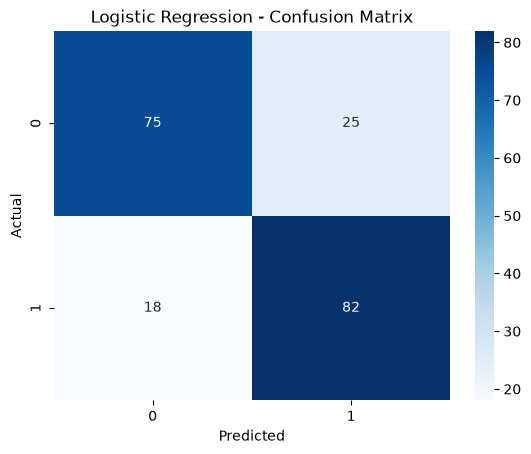

In [3]:

vec = TfidfVectorizer(max_features=10000)
Xtr = vec.fit_transform(train_texts)
Xte = vec.transform(test_texts)

lr = LogisticRegression(max_iter=300)
lr.fit(Xtr, train_labels)
pred_lr = lr.predict(Xte)

def metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary')
    print(f"{name}: Acc={acc:.4f} Precision={p:.4f} Recall={r:.4f} F1={f1:.4f}")
    return acc, p, r, f1

metrics(test_labels, pred_lr, "Logistic Regression")

cm = confusion_matrix(test_labels, pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()


## 7.2 LSTM

Epoch 1 loss 0.6940


Epoch 2 loss 0.6596


Epoch 3 loss 0.6063
LSTM: Acc=0.4800 Precision=0.4873 Recall=0.7700 F1=0.5969


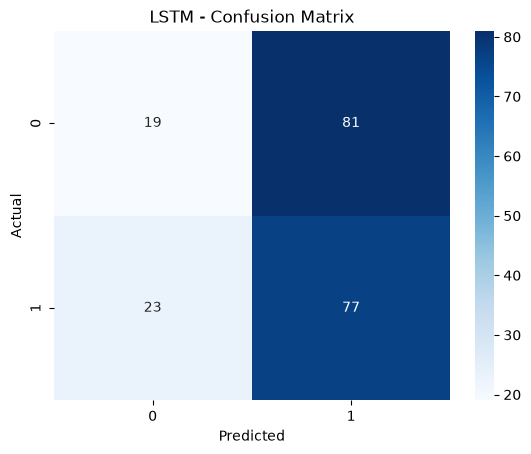

In [4]:

# Build vocab
from collections import Counter
counter = Counter()
for t in train_texts:
    counter.update(t.lower().split())
vocab = {w: i+2 for i, (w, _) in enumerate(counter.most_common(20000))}
VOCAB = len(vocab) + 2
MAXLEN = 150

def encode(text):
    ids = [vocab.get(w, 1) for w in text.lower().split()][:MAXLEN]
    if len(ids) < MAXLEN:
        ids += [0] * (MAXLEN - len(ids))
    return ids

Xtr_ids = torch.tensor([encode(t) for t in train_texts], dtype=torch.long)
Xte_ids = torch.tensor([encode(t) for t in test_texts], dtype=torch.long)
ytr = torch.tensor(train_labels, dtype=torch.long)
yte = torch.tensor(test_labels, dtype=torch.long)

train_ds = TensorDataset(Xtr_ids, ytr)
test_ds = TensorDataset(Xte_ids, yte)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=32)

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb=128, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 2)
    def forward(self, x):
        e = self.emb(x)
        _, (h, _) = self.lstm(e)
        return self.fc(h[-1])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lstm_model = LSTMClassifier(VOCAB).to(device)
opt = torch.optim.Adam(lstm_model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

for epoch in range(3):
    lstm_model.train()
    total = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = lstm_model(xb)
        loss = crit(out, yb)
        loss.backward()
        opt.step()
        total += loss.item()
    print(f"Epoch {epoch+1} loss {total/len(train_loader):.4f}")

lstm_model.eval()
preds = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        out = lstm_model(xb)
        preds.extend(out.argmax(1).cpu().numpy())
pred_lstm = np.array(preds)
metrics(test_labels, pred_lstm, "LSTM")
cm = confusion_matrix(test_labels, pred_lstm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("LSTM - Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()


## 7.3 Vanilla Transformer

Epoch 1 loss 0.7421


Epoch 2 loss 0.6813


Epoch 3 loss 0.6637
Vanilla Transformer: Acc=0.5600 Precision=0.5341 Recall=0.9400 F1=0.6812


/Users/himanshu/Projects/coding/NLP Lab/venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


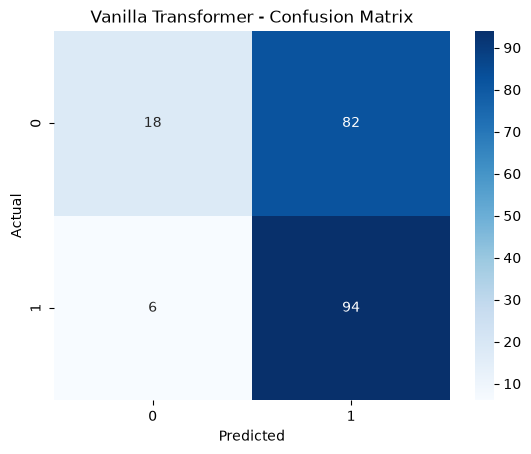

In [5]:

import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.pe = pe.unsqueeze(0)
    def forward(self, x):
        return x + self.pe[:, :x.size(1)].to(x.device)

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4, num_layers=2, dim_ff=256, max_len=150):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos = PositionalEncoding(d_model, max_len)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_ff, batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.fc = nn.Linear(d_model, 2)
    def forward(self, x):
        mask = (x == 0)
        e = self.pos(self.emb(x))
        out = self.transformer(e, src_key_padding_mask=mask)
        # mean pooling over non-pad
        m = (~mask).unsqueeze(-1).float()
        pooled = (out * m).sum(1) / m.sum(1).clamp(min=1)
        return self.fc(pooled)

tf_model = TransformerClassifier(VOCAB).to(device)
opt = torch.optim.Adam(tf_model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

for epoch in range(3):
    tf_model.train()
    total = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = tf_model(xb)
        loss = crit(out, yb)
        loss.backward()
        opt.step()
        total += loss.item()
    print(f"Epoch {epoch+1} loss {total/len(train_loader):.4f}")

tf_model.eval()
preds = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        out = tf_model(xb)
        preds.extend(out.argmax(1).cpu().numpy())
pred_tf = np.array(preds)
metrics(test_labels, pred_tf, "Vanilla Transformer")
cm = confusion_matrix(test_labels, pred_tf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Vanilla Transformer - Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()


## 7.4 BERT (Pretrained)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7921.97it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


/Users/himanshu/Projects/coding/NLP Lab/venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.432260,0.455116


BERT: Acc=0.7800 Precision=0.7979 Recall=0.7500 F1=0.7732


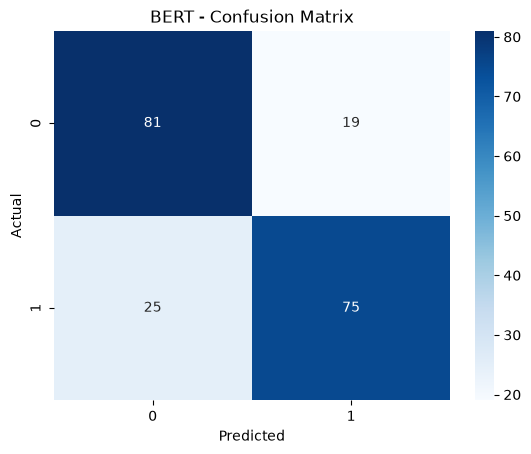

In [6]:

from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

tokenizer_bert = AutoTokenizer.from_pretrained('bert-base-uncased')
bert_model = AutoModelForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

class IMDbTorch(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer_bert(texts, truncation=True, padding=True, max_length=128, return_tensors='pt')
        self.labels = torch.tensor(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = self.labels[i]
        return item

train_dataset = IMDbTorch(train_texts, train_labels)
test_dataset = IMDbTorch(test_texts, test_labels)

args = TrainingArguments(
    output_dir='./bert_out',
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    logging_steps=50,
    eval_strategy='epoch',
    save_strategy='no',
    report_to=[]
)

trainer = Trainer(model=bert_model, args=args, train_dataset=train_dataset, eval_dataset=test_dataset)
trainer.train()

pred_out = trainer.predict(test_dataset)
pred_bert = np.argmax(pred_out.predictions, axis=1)
metrics(test_labels, pred_bert, "BERT")
cm = confusion_matrix(test_labels, pred_bert)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("BERT - Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()


## 7.5 Comparative Analysis

In [7]:

import pandas as pd
rows = []
for name, pred in [("Logistic Regression", pred_lr), ("LSTM", pred_lstm),
                   ("Vanilla Transformer", pred_tf), ("BERT", pred_bert)]:
    acc = accuracy_score(test_labels, pred)
    p, r, f1, _ = precision_recall_fscore_support(test_labels, pred, average='binary')
    rows.append({"Model": name, "Accuracy": acc, "Precision": p, "Recall": r, "F1": f1})
df = pd.DataFrame(rows)
print(df.to_string(index=False))


              Model  Accuracy  Precision  Recall       F1
Logistic Regression     0.785   0.766355    0.82 0.792271
               LSTM     0.480   0.487342    0.77 0.596899
Vanilla Transformer     0.560   0.534091    0.94 0.681159
               BERT     0.780   0.797872    0.75 0.773196
